# Data format vs. output tokens: test 4 (Claude Haiku 4.5)

## 1. Introduction

**Question:** when the data in a prompt is written as CSV, JSON, XML, a Markdown table or prose, does the model spend a different number of **output tokens** writing code for it?

**Hypothesis:** formats that are harder to parse (prose, XML) make the model write longer code than formats with a standard parser (CSV, JSON).

**Design**

| | |
|---|---|
| Task | the parse task: write `q1(text)`, `q2(text)`, `q3(text)`, functions that receive the data as a string and parse it. This is how people usually ask for code; the earlier "copy the data into the code" version is dropped |
| Data formats | `csv`, `json`, `markdown`, `xml`, `prose`: the same 20 rows, written five ways |
| Tasks | 12, each with its own 20-row sample: `t41`–`t46` are the earlier parse tasks (`t21`–`t26`) again, `t47`–`t52` are new (new leagues, columns and questions) |
| Instructions | the structured prompt only (labeled sections, numbered requirements) |
| Model | `claude-haiku-4-5`, temperature 0.7, max 4,096 output tokens, no extended thinking, so output tokens are exactly the visible reply |
| Runs | 40 per task × format, so 12 × 5 × 40 = 2,400 calls, sent as Message Batches (half price; every request is independent) |
| Validity | the code runs on a hidden 20-row sample from another league, and doesn't hard-code the prompt's data. Answers aren't graded |

In [1]:
import json
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy import stats

sys.path.insert(0, "../scripts")
from make_format_tasks import ALL_TASKS as TASKS  # task definitions: leagues, columns
from make_format_tasks import NEW_TASKS, format_id, render_all

SEED = 42
N_PERM = 10_000
RESULTS_CSV = Path("../data/format_results.csv")
RAW_DIR = Path("../data/raw_format")
TASKS_DIR = Path("../format_tasks")
MODEL = "claude-haiku-4-5"
N_ROWS = 20
LIST_PRICES = (1.00, 5.00)   # USD per million tokens (input, output)
BATCH_PRICES = (0.50, 2.50)  # what this run paid

# Roughly compact -> wordy. Colors match eda1-eda3; the order keeps neighbors distinguishable.
DATA_FORMATS = ["csv", "json", "markdown", "xml", "prose"]
DATA_COLORS = {"csv": "#008300", "json": "#1d6fb8", "markdown": "#d4762c", "xml": "#4a3aa7", "prose": "#e87ba4"}
DATA_MARKERS = {"csv": "o", "json": "v", "markdown": "^", "xml": "s", "prose": "D"}

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ae",
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "font.size": 10,
})

responses = pd.read_csv(RESULTS_CSV)
responses = responses[responses["model"] == MODEL].copy()
responses["task"] = responses["task_id"].str[4:]  # t41_side_winrate -> side_winrate
NEW_IDS = {format_id(t) for t in NEW_TASKS}
responses["task set"] = np.where(responses["task_id"].isin(NEW_IDS), "new (t47–t52)", "original (t41–t46)")
responses["data_format"] = pd.Categorical(responses["data_format"], DATA_FORMATS, ordered=True)
responses["custom_id"] = (responses["task_id"] + "__" + responses["data_format"].astype(str)
                          + "__run" + responses["run"].map("{:02d}".format))
responses["total_tokens"] = responses["input_tokens"] + responses["output_tokens"]
responses["reply"] = [(RAW_DIR / f"{cid}.txt").read_text(encoding="utf-8") if (RAW_DIR / f"{cid}.txt").exists() else ""
                      for cid in responses["custom_id"]]
TASK_NAMES = sorted(responses["task"].unique())

spent = (responses["input_tokens"].sum() * BATCH_PRICES[0] + responses["output_tokens"].sum() * BATCH_PRICES[1]) / 1e6
print(f"{len(responses)} responses, {responses['task'].nunique()} tasks, "
      f"{responses['run'].max()} runs per task × format")
print(f"tokens: {responses['input_tokens'].sum():,} input, {responses['output_tokens'].sum():,} output "
      f"-> about ${spent:.2f} at batch prices")

2400 responses, 12 tasks, 40 runs per task × format
tokens: 2,489,000 input, 1,137,738 output -> about $4.09 at batch prices


## 2. Data source

The rows come from [Oracle's Elixir](https://oracleselixir.com)'s 2025 League of Legends esports match data. `scripts/make_format_tasks.py` builds both sets of tasks:

- **Original 6** (`t41`–`t46`): the same samples as the earlier parse version (`t21`–`t26`), read from each parse task's `sample.json` and `hidden.json`. Their CSV, XML and prose files are byte-identical to the earlier ones.
- **New 6** (`t47`–`t52`): sampled the same way (fixed seed, games with complete data only) from leagues, columns and questions the original tasks don't use. They test whether the format effect holds beyond the original 6 questions.

For every task:

- **Prompt sample:** 20 rows from one league, shown to the model.
- **Hidden sample:** 20 rows from a different league with no shared team or player names, used only by the validity check.
- Team tasks have one row per team per game (10 games × 2 teams); player tasks have one row per player (20 players, one position).

## 3. The 12 tasks

In [2]:
def questions(task_dir):
    text = (task_dir / "structured.txt").read_text(encoding="utf-8")
    return [re.sub(r"^\d+\. Define a function ", "", line) for line in text.splitlines() if "Define a function" in line]

task_table = pd.DataFrame([
    {"task": format_id(t)[4:], "set": "new" if t in NEW_TASKS else "original",
     "rows": "team per game" if t["kind"] == "team" else f"player ({t['position']})",
     "prompt league": t["league"], "hidden league": t["hidden_league"], "columns": ", ".join(t["columns"]),
     **{f"q{i}": q for i, q in enumerate(questions(TASKS_DIR / format_id(t)), start=1)}}
    for t in TASKS
]).set_index("task")
with pd.option_context("display.max_colwidth", None):
    display(task_table)

,set,rows,prompt league,hidden league,columns,q1,q2,q3
task,,,,,,,,
side_winrate,original,team per game,LCK,LFL,"game, team, side, result, game_minutes","`q1(text)` that returns the win rate of blue-side teams, as a number between 0 and 1.",`q2(text)` that returns the average length in minutes of the games won by the red-side team.,`q3(text)` that returns the name of the team with the most wins.
gold_lead,original,team per game,LEC,LCK,"game, team, side, result, gold_diff_15",`q1(text)` that returns the average gold difference at 15 minutes of the winning teams.,`q2(text)` that returns how many teams won despite a negative gold difference at 15 minutes.,"`q3(text)` that returns the win rate of teams that were ahead in gold at 15 minutes, as a number between 0 and 1."
objectives,original,team per game,LAS,LEC,"game, team, result, first_dragon, dragons, barons, towers","`q1(text)` that returns the win rate of teams that took the first dragon, as a number between 0 and 1.",`q2(text)` that returns the average number of barons taken by winning teams.,`q3(text)` that returns the total number of towers destroyed across all rows.
mid_kda,original,player (mid),NLC,LJL,"player, team, champion, kills, deaths, assists, result","`q1(text)` that returns the name of the player with the highest KDA, where KDA = (kills + assists) / max(deaths, 1).",`q2(text)` that returns the average number of kills in games that were won.,`q3(text)` that returns the name of the most-picked champion.
jungle_picks,original,player (jng),LJL,EM,"player, champion, result, deaths",`q1(text)` that returns the number of different champions played.,`q2(text)` that returns the name of the champion with the best win rate among champions played at least twice (return None if no champion was played twice).,`q3(text)` that returns the average number of deaths in games that were lost.
support_vision,original,player (sup),EM,LJL,"player, team, result, vision_score, wards_placed, control_wards",`q1(text)` that returns the average vision score of players who won minus the average vision score of players who lost.,`q2(text)` that returns the name of the player who placed the most wards.,`q3(text)` that returns how many players bought at least 15 control wards.
first_tower,new,team per game,LCKC,TCL,"game, team, result, first_tower, void_grubs, heralds","`q1(text)` that returns the win rate of teams that took the first tower, as a number between 0 and 1.",`q2(text)` that returns the average number of void grubs taken by winning teams.,`q3(text)` that returns how many teams took at least one herald and still lost.
early_kills,new,team per game,PCS,TCL,"game, team, side, result, kills_at_15, xp_diff_15",`q1(text)` that returns the average number of kills at 15 minutes of red-side teams.,`q2(text)` that returns the name of the team with the largest experience difference at 15 minutes.,`q3(text)` that returns how many teams won despite a negative experience difference at 15 minutes.
inhibitors,new,team per game,LTA N,LVP SL,"game, team, result, game_minutes, inhibitors, tower_damage",`q1(text)` that returns the average number of inhibitors destroyed by winning teams.,`q2(text)` that returns the average damage to towers of losing teams.,`q3(text)` that returns the game label (for example G01) of the longest game.


## 4. The 5 data formats

The first 2 rows of the `side_winrate` task, as each format writes them. The prompt contains all 20 rows in exactly one format.

In [3]:
example_task = TASKS[0]
example_rows = json.loads((TASKS_DIR / format_id(example_task) / "sample.json").read_text(encoding="utf-8"))[:2]
for fmt, text in render_all(example_rows, example_task).items():
    print(f"--- {fmt} ---\n{text}\n")

--- csv ---
game,team,side,result,game_minutes
G01,DN Freecs,blue,loss,34.1
G01,Dplus KIA,red,win,34.1

--- json ---
[
  {
    "game": "G01",
    "team": "DN Freecs",
    "side": "blue",
    "result": "loss",
    "game_minutes": 34.1
  },
  {
    "game": "G01",
    "team": "Dplus KIA",
    "side": "red",
    "result": "win",
    "game_minutes": 34.1
  }
]

--- xml ---
<rows>
  <row><game>G01</game><team>DN Freecs</team><side>blue</side><result>loss</result><game_minutes>34.1</game_minutes></row>
  <row><game>G01</game><team>Dplus KIA</team><side>red</side><result>win</result><game_minutes>34.1</game_minutes></row>
</rows>

--- markdown ---
| game | team | side | result | game_minutes |
|---|---|---|---|---|
| G01 | DN Freecs | blue | loss | 34.1 |
| G01 | Dplus KIA | red | win | 34.1 |

--- prose ---
In game G01, DN Freecs played on the blue side and lost; the game lasted 34.1 minutes. In game G01, Dplus KIA played on the red side and won; the game lasted 34.1 minutes.



In [4]:
# One full prompt, exactly as the model received it (after the system prompt
# "You are a Python programmer. Reply with only Python code.")
template = (TASKS_DIR / format_id(example_task) / "structured.txt").read_text(encoding="utf-8")
data = (TASKS_DIR / format_id(example_task) / "data_json.txt").read_text(encoding="utf-8").strip()
print(template.replace("{DATA}", data))

## Goal
Write Python functions that answer three questions about data in the format below.

## Data
Here is a sample of some League of Legends esports match data, one row per team per game:

[
  {
    "game": "G01",
    "team": "DN Freecs",
    "side": "blue",
    "result": "loss",
    "game_minutes": 34.1
  },
  {
    "game": "G01",
    "team": "Dplus KIA",
    "side": "red",
    "result": "win",
    "game_minutes": 34.1
  },
  {
    "game": "G02",
    "team": "BNK FEARX",
    "side": "blue",
    "result": "loss",
    "game_minutes": 40.1
  },
  {
    "game": "G02",
    "team": "Gen.G",
    "side": "red",
    "result": "win",
    "game_minutes": 40.1
  },
  {
    "game": "G03",
    "team": "Dplus KIA",
    "side": "blue",
    "result": "win",
    "game_minutes": 27.5
  },
  {
    "game": "G03",
    "team": "BNK FEARX",
    "side": "red",
    "result": "loss",
    "game_minutes": 27.5
  },
  {
    "game": "G04",
    "team": "DRX",
    "side": "blue",
    "result": "win",
    "game_minu

## 5. Data quality

What came back, and whether anything needs cleaning. The input data is fixed and needs none; the checks are on the **responses**:

- every planned request should be here exactly once;
- `stop_reason` should be `end_turn`. `max_tokens` would mean a reply was cut off, which would shorten its output count;
- no prompt caching (it would change how input tokens are reported);
- validity per format.

**Rule:** invalid responses stay in the token analysis, because they still cost tokens. Section 9 repeats the main comparisons on valid responses only.

In [5]:
expected = {f"{format_id(t)}__{d}__run{r:02d}" for t in TASKS for d in DATA_FORMATS for r in range(1, 41)}
got = set(responses["custom_id"])
print(f"expected {len(expected)}, received {len(got)}, missing {len(expected - got)}, "
      f"duplicates {responses['custom_id'].duplicated().sum()}")
print("stop reasons:", responses["stop_reason"].value_counts().to_dict())
print("responses using prompt caching:", int((responses["cache_tokens"] > 0).sum()))
print("saved replies found:", int((responses["reply"] != "").sum()))

def wilson(k, n, z=1.96):
    p = k / n
    center = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return center - half, center + half

validity = responses.groupby("data_format", observed=True).agg(
    n=("passed_all", "size"), valid=("passed_all", "sum"), tokens=("total_tokens", "sum"))
validity["rate"] = validity["valid"] / validity["n"]
validity["low"], validity["high"] = wilson(validity["valid"], validity["n"])
validity["tests passed: 0 / 1 / 2"] = [
    " / ".join(str(((responses["data_format"] == d) & (responses["tests_passed"] == k)).sum()) for k in (0, 1, 2))
    for d in validity.index]
chi_p = stats.chi2_contingency(pd.crosstab(responses["data_format"], responses["passed_all"]))[1]
print(f"\nvalidity depends on format? chi-square p = {chi_p:.4f}")
validity[["n", "valid", "rate", "low", "high", "tests passed: 0 / 1 / 2"]].round(3)

expected 2400, received 2400, missing 0, duplicates 0
stop reasons: {'end_turn': 2400}
responses using prompt caching: 0
saved replies found: 2400

validity depends on format? chi-square p = 0.0000


,n,valid,rate,low,high,tests passed: 0 / 1 / 2
data_format,,,,,,
csv,480,470,0.979,0.962,0.989,1 / 9 / 470
json,480,471,0.981,0.965,0.990,0 / 9 / 471
markdown,480,185,0.385,0.343,0.430,0 / 295 / 185
xml,480,391,0.815,0.777,0.847,1 / 88 / 391
prose,480,438,0.912,0.884,0.935,0 / 42 / 438


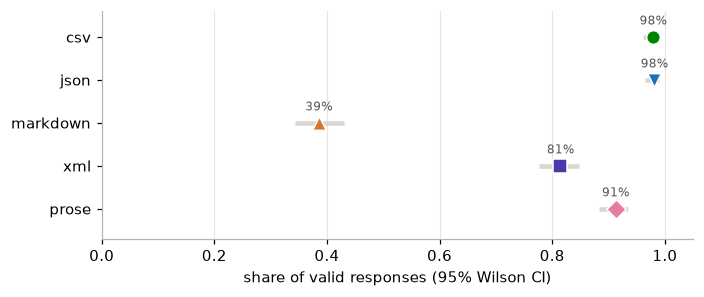

data_format,csv,json,markdown,xml,prose
task,,,,,
bot_farm,1.00,1.00,0.68,0.98,0.00
early_kills,1.00,1.00,0.05,0.95,1.00
first_tower,1.00,0.78,0.08,1.00,1.00
gold_lead,1.00,1.00,0.10,0.82,1.00
inhibitors,1.00,1.00,0.25,0.85,1.00
jungle_early,1.00,1.00,0.92,0.20,1.00
jungle_picks,0.82,1.00,0.60,1.00,0.98
mid_kda,0.98,1.00,0.48,0.55,1.00
objectives,1.00,1.00,0.15,1.00,1.00


In [6]:
fig, ax = plt.subplots(figsize=(6.5, 2.8))
for i, d in enumerate(DATA_FORMATS):
    r = validity.loc[d]
    ax.hlines(i, r["low"], r["high"], color="#d8d7d1", linewidth=3, zorder=1)
    ax.scatter(r["rate"], i, s=80, color=DATA_COLORS[d], marker=DATA_MARKERS[d], zorder=2, edgecolor="white", linewidth=1)
    ax.annotate(f"{r['rate']:.0%}", (r["rate"], i), xytext=(0, 8), textcoords="offset points",
                ha="center", fontsize=8, color="#52514e")
ax.set_yticks(range(len(DATA_FORMATS)), DATA_FORMATS)
ax.set_ylim(-0.6, len(DATA_FORMATS) - 0.3)
ax.set_xlim(0, 1.05)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("share of valid responses (95% Wilson CI)")
plt.tight_layout()
plt.show()

# by task: a format that fails on one task only shows up here
responses.pivot_table(index="task", columns="data_format", values="passed_all", aggfunc="mean", observed=True).round(2)

## 6. Input tokens

The same prompt always splits into the same tokens, so every repeat of a prompt reports the same input count: there's no noise, and differences between formats are exact (the method of `eda2` section 1). Each prompt holds the same 20 rows, so the extra cost of a format can be stated per data row.

In [7]:
cells_ = responses.groupby(["task", "data_format"], observed=True)["input_tokens"]
print("prompts whose runs all had the same input count:", (cells_.nunique() == 1).sum(), "of", cells_.ngroups)

inputs = responses.drop_duplicates(["task", "data_format"])
per_prompt = inputs.pivot_table(index="task", columns="data_format", values="input_tokens", observed=True)[DATA_FORMATS]
input_table = pd.DataFrame({
    "mean input tokens": per_prompt.mean(),
    "× csv": (per_prompt.div(per_prompt["csv"], axis=0)).mean(),
    "extra tokens per row vs csv": (per_prompt.sub(per_prompt["csv"], axis=0) / N_ROWS).mean(),
})
display(per_prompt)
input_table.round(2)

prompts whose runs all had the same input count: 60 of 60


data_format,csv,json,markdown,xml,prose
task,,,,,
bot_farm,673.0,1599.0,803.0,1523.0,956.0
early_kills,578.0,1561.0,730.0,1555.0,958.0
first_tower,631.0,1576.0,781.0,1520.0,973.0
gold_lead,534.0,1304.0,644.0,1238.0,861.0
inhibitors,583.0,1490.0,781.0,1394.0,875.0
jungle_early,579.0,1619.0,752.0,1669.0,976.0
jungle_picks,480.0,1056.0,572.0,940.0,617.0
mid_kda,675.0,1625.0,847.0,1369.0,883.0
objectives,625.0,1612.0,816.0,1436.0,969.0


,mean input tokens,× csv,extra tokens per row vs csv
data_format,,,
csv,605.42,1.00,0.00
json,1503.92,2.48,44.92
markdown,753.75,1.25,7.42
xml,1425.08,2.35,40.98
prose,897.25,1.48,14.59


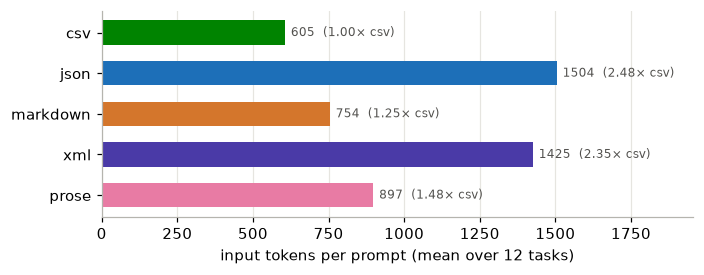

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 2.6))
y = np.arange(len(DATA_FORMATS))
ax.barh(y, input_table["mean input tokens"], color=[DATA_COLORS[d] for d in DATA_FORMATS], height=0.6)
for i, d in enumerate(DATA_FORMATS):
    ax.annotate(f"{input_table.loc[d, 'mean input tokens']:.0f}  ({input_table.loc[d, '× csv']:.2f}× csv)",
                (input_table.loc[d, "mean input tokens"], i), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=8, color="#52514e")
ax.set_yticks(y, DATA_FORMATS)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("input tokens per prompt (mean over 12 tasks)")
ax.set_xlim(0, input_table["mean input tokens"].max() * 1.3)
plt.tight_layout()
plt.show()

## 7. Output tokens

Unlike input, output varies from run to run: each reply is a new sample. This section describes the 2,400 output counts. Section 9 tests whether the differences are bigger than chance.

In [9]:
rng = np.random.default_rng(SEED)

def boot_ci(values, n=5000):
    values = np.asarray(values)
    means = rng.choice(values, (n, len(values))).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])

summary = responses.groupby("data_format", observed=True)["output_tokens"].agg(["mean", "median", "std", "min", "max"])
summary[["95% CI low", "95% CI high"]] = [boot_ci(responses.loc[responses["data_format"] == d, "output_tokens"])
                                         for d in DATA_FORMATS]
summary["× csv (mean)"] = summary["mean"] / summary.loc["csv", "mean"]
summary.round(1)

,mean,median,std,min,max,95% CI low,95% CI high,× csv (mean)
data_format,,,,,,,,
csv,460.0,459.0,88.9,227,1235,452.7,468.1,1.0
json,329.9,304.0,208.3,187,1788,312.4,350.2,0.7
markdown,566.7,564.0,68.1,282,885,560.4,572.8,1.2
xml,450.7,445.0,108.3,274,2198,442.0,461.3,1.0
prose,563.0,543.5,96.8,322,1346,554.6,571.8,1.2


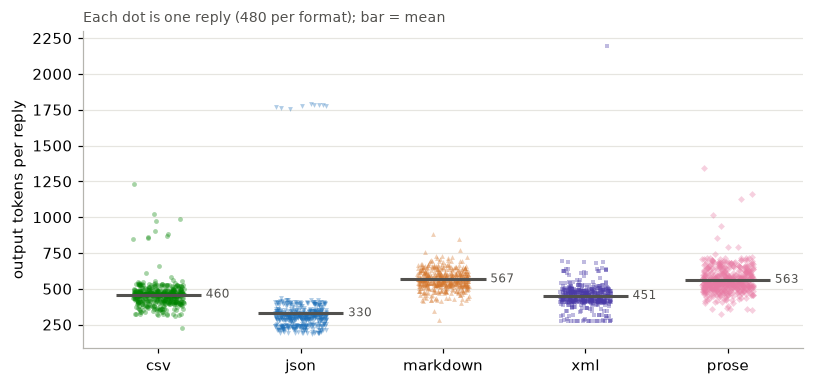

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
jitter = np.random.default_rng(SEED)
for i, d in enumerate(DATA_FORMATS):
    vals = responses.loc[responses["data_format"] == d, "output_tokens"]
    ax.scatter(i + jitter.uniform(-0.18, 0.18, len(vals)), vals, s=10, alpha=0.35, color=DATA_COLORS[d],
               marker=DATA_MARKERS[d], linewidth=0)
    lo, hi = summary.loc[d, ["95% CI low", "95% CI high"]]
    ax.hlines(summary.loc[d, "mean"], i - 0.3, i + 0.3, color="#52514e", linewidth=2)
    ax.annotate(f"{summary.loc[d, 'mean']:.0f}", (i + 0.3, summary.loc[d, "mean"]), xytext=(3, 0),
                textcoords="offset points", va="center", fontsize=8, color="#52514e")
ax.set_xticks(range(len(DATA_FORMATS)), DATA_FORMATS)
ax.set_ylabel("output tokens per reply")
ax.grid(axis="x", visible=False)
ax.set_title(f"Each dot is one reply ({len(responses) // len(DATA_FORMATS)} per format); bar = mean", loc="left", fontsize=9, color="#52514e")
plt.tight_layout()
plt.show()

**By task.** Mean output tokens per task × format, then each task relative to its own CSV mean: a gray dot per task, a large marker for the average across tasks. The formats are categories, so the dots aren't connected. If a format's dots all sit on the same side of the CSV line, the effect isn't driven by one task.

data_format,csv,json,markdown,xml,prose
task,,,,,
bot_farm,361.0,229.0,506.0,411.0,510.0
early_kills,444.0,331.0,532.0,435.0,515.0
first_tower,461.0,654.0,649.0,465.0,656.0
gold_lead,459.0,321.0,517.0,478.0,518.0
inhibitors,431.0,246.0,543.0,394.0,528.0
jungle_early,480.0,316.0,607.0,448.0,612.0
jungle_picks,565.0,399.0,548.0,513.0,528.0
mid_kda,456.0,327.0,543.0,519.0,556.0
objectives,469.0,292.0,578.0,415.0,672.0


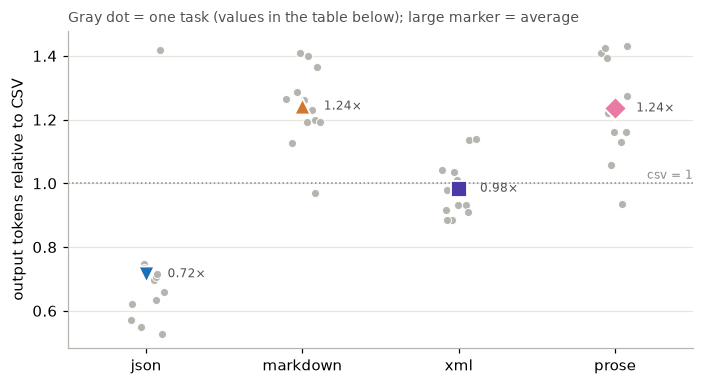

data_format,csv,json,markdown,xml,prose
task,,,,,
bot_farm,1.0,0.63,1.40,1.14,1.41
early_kills,1.0,0.75,1.20,0.98,1.16
first_tower,1.0,1.42,1.41,1.01,1.42
gold_lead,1.0,0.70,1.13,1.04,1.13
inhibitors,1.0,0.57,1.26,0.91,1.23
jungle_early,1.0,0.66,1.26,0.93,1.27
jungle_picks,1.0,0.71,0.97,0.91,0.93
mid_kda,1.0,0.72,1.19,1.14,1.22
objectives,1.0,0.62,1.23,0.88,1.43


In [11]:
task_means = responses.pivot_table(index="task", columns="data_format", values="output_tokens",
                                   aggfunc="mean", observed=True)[DATA_FORMATS]
relative = task_means.div(task_means["csv"], axis=0)
display(task_means.round(0))

fig, ax = plt.subplots(figsize=(6.5, 3.6))
others = DATA_FORMATS[1:]  # CSV is the reference line at 1
jitter = np.random.default_rng(SEED)
for i, d in enumerate(others):
    ax.scatter(i + jitter.uniform(-0.12, 0.12, len(relative)), relative[d], s=28, color="#b5b4ae",
               edgecolor="white", linewidth=0.6, zorder=2)
    ax.scatter(i, relative[d].mean(), s=110, color=DATA_COLORS[d], marker=DATA_MARKERS[d], zorder=3,
               edgecolor="white", linewidth=1.2)
    ax.annotate(f"{relative[d].mean():.2f}×", (i, relative[d].mean()), xytext=(14, 0), textcoords="offset points",
                va="center", fontsize=8, color="#52514e")
ax.axhline(1, color="#8a8984", linewidth=1, linestyle=":")
ax.annotate("csv = 1", (len(others) - 0.5, 1), xytext=(0, 3), textcoords="offset points", ha="right",
            fontsize=8, color="#8a8984")
ax.set_xticks(range(len(others)), others)
ax.set_xlim(-0.5, len(others) - 0.5)
ax.set_ylabel("output tokens relative to CSV")
ax.set_title("Gray dot = one task (values in the table below); large marker = average", loc="left",
             fontsize=9, color="#52514e")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()
relative.round(2)

**Run-to-run variability.** For each prompt (task × format), the coefficient of variation (standard deviation / mean) over its 40 runs. Higher means the same prompt gives less predictable token counts.

In [12]:
cv = responses.groupby(["task", "data_format"], observed=True)["output_tokens"].agg(lambda s: s.std() / s.mean()).unstack()
display(cv[DATA_FORMATS].round(3))
print("median CV:", cv[DATA_FORMATS].median().round(3).to_dict())
print("Friedman test (same tasks, 5 formats): p =", round(stats.friedmanchisquare(*[cv[d] for d in DATA_FORMATS]).pvalue, 4))

data_format,csv,json,markdown,xml,prose
task,,,,,
bot_farm,0.100,0.084,0.094,0.121,0.210
early_kills,0.017,0.174,0.090,0.036,0.050
first_tower,0.027,0.938,0.111,0.018,0.087
gold_lead,0.040,0.107,0.133,0.043,0.093
inhibitors,0.082,0.078,0.100,0.098,0.080
jungle_early,0.108,0.053,0.078,0.191,0.123
jungle_picks,0.311,0.033,0.067,0.093,0.150
mid_kda,0.218,0.130,0.075,0.128,0.083
objectives,0.096,0.041,0.062,0.024,0.282


median CV: {'csv': 0.098, 'json': 0.085, 'markdown': 0.092, 'xml': 0.096, 'prose': 0.09}
Friedman test (same tasks, 5 formats): p = 0.8889


**How many runs are enough?** The mean output of each format using only runs 1..N, averaged over tasks. Earlier experiments used 5 runs; where the lines flatten, more runs stop changing the answer.

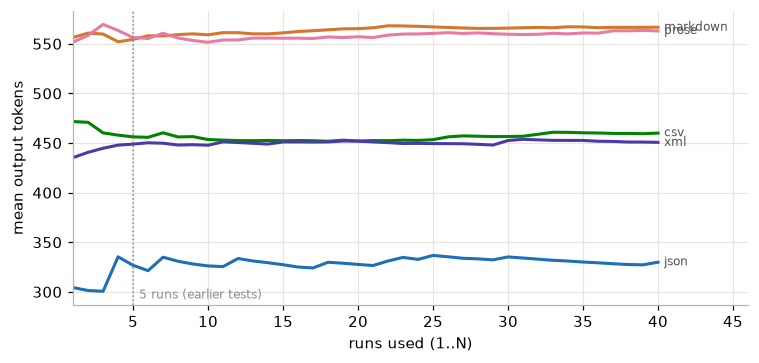

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.4))
ns = np.arange(1, responses["run"].max() + 1)
for d in DATA_FORMATS:
    sub = responses[responses["data_format"] == d]
    curve = [sub[sub["run"] <= n].groupby("task")["output_tokens"].mean().mean() for n in ns]
    ax.plot(ns, curve, color=DATA_COLORS[d], linewidth=2)
    ax.annotate(d, (ns[-1], curve[-1]), xytext=(4, 0), textcoords="offset points", va="center",
                fontsize=8, color="#52514e")
ax.axvline(5, color="#8a8984", linewidth=1, linestyle=":")
ax.annotate("5 runs (earlier tests)", (5, ax.get_ylim()[0]), xytext=(4, 4), textcoords="offset points",
            fontsize=8, color="#8a8984")
ax.set_xlabel("runs used (1..N)")
ax.set_ylabel("mean output tokens")
ax.set_xlim(1, ns[-1] + 6)
plt.tight_layout()
plt.show()

## 8. What the output tokens go to

Output tokens are spent on code, comments, docstrings and any text outside the code block. These measures come from the saved replies (`data/raw_format/`) and are counted in lines or characters, since only the total token count is reported per reply.

**Parse approach:** which tool the code uses to read the data, detected from the code (a reply can use several): the `csv` module, `json`, an XML parser, regular expressions, or plain string splitting (`.split(...)`).

In [14]:
TRIPLE = '"' * 3

def anatomy(reply):
    fence = re.findall(r"```[ \t]*(?:python|py)?[ \t]*\n(.*?)```", reply, re.DOTALL | re.IGNORECASE)
    code_ = max(fence, key=len) if fence else reply
    lines = code_.splitlines()
    doc_lines, in_doc = 0, False
    for line in lines:
        n = line.count(TRIPLE)
        if in_doc or n:
            doc_lines += 1
        if n % 2 == 1:
            in_doc = not in_doc
    return {
        "code lines": sum(1 for l in lines if l.strip()),
        "comment lines": sum(1 for l in lines if l.strip().startswith("#")),
        "docstring lines": doc_lines,
        "functions defined": len(re.findall(r"^\s*def ", code_, re.MULTILINE)),
        "text outside code (chars)": len(reply.strip()) - len(code_.strip()) if fence else 0,
        "uses csv module": bool(re.search(r"\bcsv\.|import csv", code_)),
        "uses json": bool(re.search(r"\bjson\.loads|import json", code_)),
        "uses XML parser": bool(re.search(r"ElementTree|xml\.dom|minidom|lxml", code_)),
        "uses regex": bool(re.search(r"\bre\.(?:search|findall|match|compile|finditer|sub|split)", code_)),
        "uses .split(": ".split(" in code_,
    }

anat = pd.concat([responses[["task", "data_format", "output_tokens", "passed_all"]].reset_index(drop=True),
                  pd.DataFrame([anatomy(r) for r in responses["reply"]])], axis=1)
anat_table = anat.groupby("data_format", observed=True).mean(numeric_only=True).drop(columns=["passed_all"])
anat_table.T.round(2)

data_format,csv,json,markdown,xml,prose
output_tokens,460.04,329.92,566.69,450.70,562.95
code lines,39.78,26.89,48.34,33.87,40.98
comment lines,0.36,0.23,2.77,0.29,1.70
docstring lines,2.57,5.87,2.30,3.08,3.44
functions defined,3.00,3.01,3.04,3.07,3.44
text outside code (chars),14.00,14.00,14.00,13.94,13.45
uses csv module,0.01,0.00,0.04,0.00,0.00
uses json,0.00,0.99,0.00,0.00,0.00
uses XML parser,0.00,0.00,0.00,0.86,0.00
uses regex,0.00,0.00,0.00,0.15,0.98


In [15]:
# How much of the output-token gap do code lines explain? Tokens per non-blank code line, by format.
per_line = anat.groupby("data_format", observed=True).apply(
    lambda g: g["output_tokens"].sum() / g["code lines"].sum(), include_groups=False).rename("output tokens per code line")
print(per_line.round(1).to_string())
print("\ncorrelation of output tokens with code lines:", round(anat["output_tokens"].corr(anat["code lines"]), 3))

data_format
csv         11.6
json        12.3
markdown    11.7
xml         13.3
prose       13.7

correlation of output tokens with code lines: 0.91


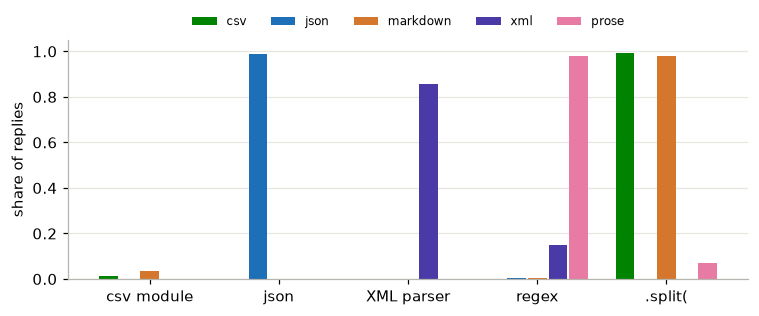

In [16]:
fig, ax = plt.subplots(figsize=(7, 3))
approaches = ["uses csv module", "uses json", "uses XML parser", "uses regex", "uses .split("]
width = 0.16
for i, d in enumerate(DATA_FORMATS):
    ax.bar(np.arange(len(approaches)) + (i - 2) * width, anat_table.loc[d, approaches], width * 0.9,
           color=DATA_COLORS[d], label=d)
ax.set_xticks(np.arange(len(approaches)), [a.removeprefix("uses ") for a in approaches])
ax.set_ylabel("share of replies")
ax.set_ylim(0, 1.05)
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.15))
plt.tight_layout()
plt.show()

**One example reply per format** (`side_winrate` task): the reply whose output count is closest to that format's median for the task, so it's typical rather than extreme.

In [17]:
example = responses[responses["task"] == "side_winrate"]
for d in DATA_FORMATS:
    sub = example[example["data_format"] == d]
    if sub.empty:
        continue
    row = sub.iloc[(sub["output_tokens"] - sub["output_tokens"].median()).abs().argmin()]
    print(f"=== {d}: run {row['run']}, {row['output_tokens']} output tokens, valid={row['passed_all']} ===")
    print(row["reply"].strip(), "\n")

=== csv: run 22, 465 output tokens, valid=True ===
```python
def q1(text):
    """Return the win rate of blue-side teams."""
    lines = text.strip().split('\n')[1:]  # Skip header
    blue_wins = 0
    blue_total = 0
    
    for line in lines:
        parts = line.split(',')
        side = parts[2]
        result = parts[3]
        
        if side == 'blue':
            blue_total += 1
            if result == 'win':
                blue_wins += 1
    
    return blue_wins / blue_total if blue_total > 0 else 0


def q2(text):
    """Return the average length in minutes of games won by red-side teams."""
    lines = text.strip().split('\n')[1:]  # Skip header
    red_win_lengths = []
    
    for line in lines:
        parts = line.split(',')
        side = parts[2]
        result = parts[3]
        game_minutes = float(parts[4])
        
        if side == 'red' and result == 'win':
            red_win_lengths.append(game_minutes)
    
    return sum(red_win_lengths) / len(red_win_l

## 9. Statistical follow-up

**Permutation test (eda2's method).** For a pair of formats, take the gap in mean log output tokens within each task (both formats share the same questions and data), and average it over the 12 tasks. Shuffling the format labels within each task 10,000 times shows how large a gap chance alone produces. The gap is reported as a ratio: 1.20 means 20% more output tokens than the second format.

**Holm correction.** 10 pairs are tested at once, so some would look significant by luck. Holm's method adjusts the p-values for that; `p (Holm)` is the one to read.

**Task CI.** A 95% bootstrap interval for the ratio, from resampling the 12 tasks. It shows whether the effect holds across tasks or comes from a few.

**Overall test.** A Friedman test on the 12 task means asks whether the five formats differ at all, treating each task as a block.

`p = 0.0001` is the smallest possible value with 10,000 shuffles (none of them produced a gap that large).

In [18]:
def blocks_for(rows, a, b, column="output_tokens"):
    out = []
    for task, g in rows[rows["data_format"].isin([a, b])].groupby("task"):
        is_a = (g["data_format"] == a).to_numpy()
        if is_a.any() and (~is_a).any():
            out.append((np.log(g[column].to_numpy()), is_a, task))
    return out

def mean_gap(blocks, labels=None):
    labels = labels or [b[1] for b in blocks]
    return np.mean([y[m].mean() - y[~m].mean() for (y, _, _), m in zip(blocks, labels)])

def compare(rows, a, b):
    blocks = blocks_for(rows, a, b)
    observed = mean_gap(blocks)
    perm = np.array([mean_gap(blocks, [rng.permutation(m) for _, m, _ in blocks]) for _ in range(N_PERM)])
    p = (np.sum(np.abs(perm) >= abs(observed)) + 1) / (N_PERM + 1)
    tasks = [t for _, _, t in blocks]
    boot = [mean_gap([blocks[i] for i in rng.integers(0, len(blocks), len(blocks))]) for _ in range(2000)]
    lo, hi = np.exp(np.percentile(boot, [2.5, 97.5]))
    higher = sum(y[m].mean() > y[~m].mean() for y, m, _ in blocks)
    return {"ratio": np.exp(observed), "95% CI low": lo, "95% CI high": hi, "p": p,
            "tasks where higher": f"{higher} of {len(tasks)}"}

def holm(p):
    p = np.asarray(p)
    order = np.argsort(p)
    adjusted = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]).clip(max=1)
    out = np.empty_like(adjusted)
    out[order] = adjusted
    return out

PAIRS = [(a, b) for i, b in enumerate(DATA_FORMATS) for a in DATA_FORMATS[i + 1:]]

def effects_table(rows):
    table = pd.DataFrame([{"comparison": f"{a} / {b}", **compare(rows, a, b)} for a, b in PAIRS]).set_index("comparison")
    table["p (Holm)"] = holm(table["p"])
    table["significant"] = np.where(table["p (Holm)"] < 0.05, "yes", "no")
    return table

friedman = stats.friedmanchisquare(*[task_means[d] for d in DATA_FORMATS])
print(f"Friedman test on task means, all responses: p = {friedman.pvalue:.4f}")
effects = effects_table(responses)
effects.round(4)

Friedman test on task means, all responses: p = 0.0000


,ratio,95% CI low,95% CI high,p,tasks where higher,p (Holm),significant
comparison,,,,,,,
json / csv,0.6761,0.6193,0.7464,0.0001,1 of 12,0.0010,yes
markdown / csv,1.2404,1.1785,1.3033,0.0001,12 of 12,0.0010,yes
xml / csv,0.9754,0.9264,1.0308,0.0042,5 of 12,0.0084,yes
prose / csv,1.2254,1.1443,1.3030,0.0001,11 of 12,0.0010,yes
markdown / json,1.8346,1.6481,2.0476,0.0001,12 of 12,0.0010,yes
xml / json,1.4426,1.3207,1.5570,0.0001,11 of 12,0.0010,yes
prose / json,1.8124,1.6193,2.0345,0.0001,12 of 12,0.0010,yes
xml / markdown,0.7863,0.7293,0.8472,0.0001,0 of 12,0.0010,yes
prose / markdown,0.9879,0.9555,1.0225,0.1153,6 of 12,0.1153,no


**Robustness: valid responses only.** The same tests using only replies that passed both validity checks. If the ratios barely move, the format effect isn't caused by broken replies.

In [19]:
valid_only = responses[responses["passed_all"]]
effects_valid = effects_table(valid_only)
pd.DataFrame({
    "ratio (all)": effects["ratio"],
    "ratio (valid only)": effects_valid["ratio"],
    "95% CI low": effects_valid["95% CI low"],
    "95% CI high": effects_valid["95% CI high"],
    "p (Holm, valid only)": effects_valid["p (Holm)"],
    "significant (valid only)": effects_valid["significant"],
}).round(4)

,ratio (all),ratio (valid only),95% CI low,95% CI high,"p (Holm, valid only)",significant (valid only)
comparison,,,,,,
json / csv,0.6761,0.6641,0.6200,0.7083,0.0010,yes
markdown / csv,1.2404,1.2786,1.2223,1.3443,0.0010,yes
xml / csv,0.9754,1.0321,0.9705,1.1045,0.0010,yes
prose / csv,1.2254,1.2313,1.1681,1.3007,0.0010,yes
markdown / json,1.8346,1.9254,1.7406,2.1450,0.0010,yes
xml / json,1.4426,1.5541,1.4529,1.6642,0.0010,yes
prose / json,1.8124,1.8466,1.6581,2.0686,0.0010,yes
xml / markdown,0.7863,0.8072,0.7352,0.8824,0.0010,yes
prose / markdown,0.9879,0.9720,0.9402,1.0053,0.0511,no


**Do the new tasks agree with the original ones?** The ratios vs. CSV computed separately on the original 6 tasks and on the 6 new ones. If both halves point the same way, the effect isn't tied to the original questions.

In [20]:
halves = {}
for name, rows in responses.groupby("task set"):
    halves[name] = pd.Series({f"{a} / csv": compare(rows, a, "csv")["ratio"] for a in DATA_FORMATS[1:]})
halves = pd.DataFrame(halves)
halves["same direction"] = np.where(np.sign(np.log(halves.iloc[:, 0])) == np.sign(np.log(halves.iloc[:, 1])), "yes", "no")
display(halves.round(3))
responses.pivot_table(index="task set", columns="data_format", values="passed_all", aggfunc="mean", observed=True).round(2)

,new (t47–t52),original (t41–t46),same direction
json / csv,0.678,0.674,yes
markdown / csv,1.313,1.172,yes
xml / csv,0.956,0.995,yes
prose / csv,1.305,1.151,yes


data_format,csv,json,markdown,xml,prose
task set,,,,,
new (t47–t52),1.00,0.96,0.36,0.73,0.83
original (t41–t46),0.96,1.00,0.41,0.90,1.00


## 10. Total cost per format

What a user pays per call: input + output tokens, in dollars at list price and at the batch price this run used. **Cost per valid reply** divides everything spent by the number of valid replies, the cost of retrying until the code works.

In [21]:
cost = responses.groupby("data_format", observed=True).agg(
    input=("input_tokens", "mean"), output=("output_tokens", "mean"), total=("total_tokens", "mean"),
    valid_rate=("passed_all", "mean"))
cost["output share"] = cost["output"] / cost["total"]
cost["$ per 1,000 calls (list)"] = (cost["input"] * LIST_PRICES[0] + cost["output"] * LIST_PRICES[1]) / 1000
cost["$ per 1,000 calls (batch)"] = cost["$ per 1,000 calls (list)"] / 2
cost["$ per 1,000 valid replies (list)"] = cost["$ per 1,000 calls (list)"] / cost["valid_rate"]
cost["× csv (list)"] = cost["$ per 1,000 calls (list)"] / cost.loc["csv", "$ per 1,000 calls (list)"]
cost.round(3)

,input,output,total,valid_rate,output share,"$ per 1,000 calls (list)","$ per 1,000 calls (batch)","$ per 1,000 valid replies (list)",× csv (list)
data_format,,,,,,,,,
csv,605.417,460.035,1065.452,0.979,0.432,2.906,1.453,2.967,1.000
json,1503.917,329.917,1833.833,0.981,0.180,3.154,1.577,3.214,1.085
markdown,753.750,566.685,1320.435,0.385,0.429,3.587,1.794,9.307,1.235
xml,1425.083,450.696,1875.779,0.815,0.240,3.679,1.839,4.516,1.266
prose,897.250,562.954,1460.204,0.912,0.386,3.712,1.856,4.068,1.278


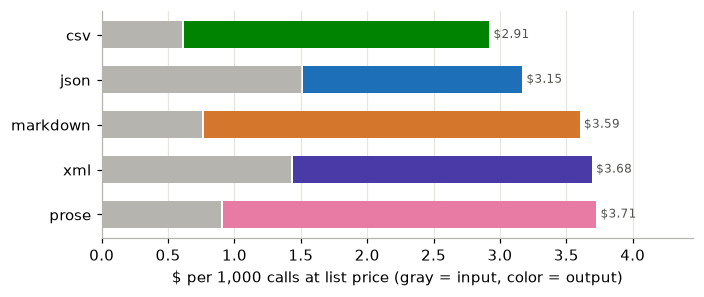

In [22]:
fig, ax = plt.subplots(figsize=(6.5, 2.8))
y = np.arange(len(DATA_FORMATS))
inp = cost["input"] * LIST_PRICES[0] / 1000
out = cost["output"] * LIST_PRICES[1] / 1000
ax.barh(y, inp, color="#b5b4ae", height=0.6, label="input")
ax.barh(y, out, left=inp + inp.max() * 0.01, color=[DATA_COLORS[d] for d in DATA_FORMATS], height=0.6, label="output")
for i, d in enumerate(DATA_FORMATS):
    ax.annotate(f"${cost.loc[d, '$ per 1,000 calls (list)']:.2f}", (inp[d] + out[d], i), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=8, color="#52514e")
ax.set_yticks(y, DATA_FORMATS)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_xlabel("$ per 1,000 calls at list price (gray = input, color = output)")
ax.set_xlim(0, (inp + out).max() * 1.2)
plt.tight_layout()
plt.show()

## 11. Findings

The numbers below are computed from the data, so they stay correct if the notebook is re-run.

In [23]:
lines = []
lines.append(f"- **Input** (exact): " + ", ".join(
    f"{d} {input_table.loc[d, 'mean input tokens']:.0f} ({input_table.loc[d, '× csv']:.2f}× csv)" for d in DATA_FORMATS) + ".")
lines.append(f"- **Output** (mean per reply): " + ", ".join(
    f"{d} {summary.loc[d, 'mean']:.0f}" for d in DATA_FORMATS) + f". Friedman test across formats: p = {friedman.pvalue:.4f}.")
sig = effects[effects["significant"] == "yes"]
if len(sig):
    lines.append("- **Significant pairs** (Holm p < 0.05): " + "; ".join(
        f"{c} = {r['ratio']:.2f}× (CI {r['95% CI low']:.2f}–{r['95% CI high']:.2f}, higher in {r['tasks where higher']} tasks)"
        for c, r in sig.iterrows()) + ".")
else:
    lines.append("- **No pair of formats differs significantly** after the Holm correction.")
held = (effects["significant"] == effects_valid["significant"]).sum()
lines.append(f"- **Valid replies only:** {held} of {len(effects)} pairs keep the same verdict.")
lines.append(f"- **Original vs. new tasks:** {(halves['same direction'] == 'yes').sum()} of {len(halves)} "
             "ratios vs. CSV point the same way in both halves.")
lines.append("- **Validity:** " + ", ".join(f"{d} {validity.loc[d, 'rate']:.0%}" for d in DATA_FORMATS)
             + f" (chi-square p = {chi_p:.4f}).")
cheapest, dearest = cost["$ per 1,000 calls (list)"].idxmin(), cost["$ per 1,000 calls (list)"].idxmax()
lines.append(f"- **Cost:** cheapest {cheapest} (${cost.loc[cheapest, '$ per 1,000 calls (list)']:.2f} per 1,000 calls), "
             f"most expensive {dearest} (${cost.loc[dearest, '$ per 1,000 calls (list)']:.2f}); "
             f"output is {cost['output share'].min():.0%}–{cost['output share'].max():.0%} of tokens.")
display(Markdown("\n".join(lines)))

- **Input** (exact): csv 605 (1.00× csv), json 1504 (2.48× csv), markdown 754 (1.25× csv), xml 1425 (2.35× csv), prose 897 (1.48× csv).
- **Output** (mean per reply): csv 460, json 330, markdown 567, xml 451, prose 563. Friedman test across formats: p = 0.0000.
- **Significant pairs** (Holm p < 0.05): json / csv = 0.68× (CI 0.62–0.75, higher in 1 of 12 tasks); markdown / csv = 1.24× (CI 1.18–1.30, higher in 12 of 12 tasks); xml / csv = 0.98× (CI 0.93–1.03, higher in 5 of 12 tasks); prose / csv = 1.23× (CI 1.14–1.30, higher in 11 of 12 tasks); markdown / json = 1.83× (CI 1.65–2.05, higher in 12 of 12 tasks); xml / json = 1.44× (CI 1.32–1.56, higher in 11 of 12 tasks); prose / json = 1.81× (CI 1.62–2.03, higher in 12 of 12 tasks); xml / markdown = 0.79× (CI 0.73–0.85, higher in 0 of 12 tasks); prose / xml = 1.26× (CI 1.15–1.37, higher in 12 of 12 tasks).
- **Valid replies only:** 10 of 10 pairs keep the same verdict.
- **Original vs. new tasks:** 4 of 4 ratios vs. CSV point the same way in both halves.
- **Validity:** csv 98%, json 98%, markdown 39%, xml 81%, prose 91% (chi-square p = 0.0000).
- **Cost:** cheapest csv ($2.91 per 1,000 calls), most expensive prose ($3.71); output is 18%–43% of tokens.

**Compared with the earlier Haiku 4.5 parse run.** CSV, XML and prose were also run in the earlier parse version (`t21`–`t26`, 5 runs, both instruction styles). Only its structured-prompt rows are compared here, with this run's original 6 tasks (the same prompts).

In [24]:
old_path = Path("../data/results_claude.csv")
if old_path.exists():
    old = pd.read_csv(old_path)
    old = old[old["task_id"].str.startswith("t2") & (old["format"] == "structured") & (old["model"] == MODEL)]
    old_means = old.groupby("data_format")["output_tokens"].agg(["mean", "size"])
    same_prompts = responses[~responses["task_id"].isin(NEW_IDS)]
    new_means = same_prompts.groupby("data_format", observed=True)["output_tokens"].agg(["mean", "size"])
    display(pd.DataFrame({"earlier run (5 runs)": old_means["mean"], "n earlier": old_means["size"],
                          "this run (40 runs)": new_means["mean"], "n this run": new_means["size"]})
            .reindex(DATA_FORMATS).round(0))
else:
    print("data/results_claude.csv not found; skipped")

,earlier run (5 runs),n earlier,this run (40 runs),n this run
data_format,,,,
csv,500.0,30.0,490.0,240
json,NaN,NaN,329.0,240
markdown,NaN,NaN,569.0,240
xml,518.0,30.0,484.0,240
prose,561.0,30.0,563.0,240
